# 06 — EfficientAD

Pilot-stage research notebook. Full benchmark is gated and has not started.

## 1. Motivation

EfficientAD combines efficient local descriptors with global feature reconstruction. This notebook currently documents the reference review, implementation and real GPU pilot. Development and the frozen benchmark remain pending.

## 2. Paper review

Read Batzner et al., WACV 2024, using https://arxiv.org/html/2303.14535v3 after CVF returned 403. Algorithms 1–2 and Tables 6–8 define this implementation. See docs/efficientad_protocol.md for the source links and detailed derivation.

## 3. Teacher provenance

The teacher is the public third-party PDN-S checkpoint from nelson1425/EfficientAD, revision fcab5146f84ae17597044ad5ddf1656ccf805401. Repository Apache-2.0; no separate weight model card. Its accompanying code describes ImageNet WideResNet101_2 distillation; that history cannot be independently attested from tensors.

## 4. Architecture

PDN convolutions use channels 3→128→256→256→384, kernels 4,4,3,4 and average pooling after the first two. Paper padding gives 64×64 output and a 33-pixel local receptive field. The student outputs 768 channels. The global autoencoder has a 64×1×1 bottleneck. Medium capacity adds wider layers and 1×1 convolutions; it has not been measured here.

## 5. Loss mathematics

Normalize teacher channels with fitting-only population moments. D=(t−s1)²; Lhard=mean(D≥its .999 quantile). Lpenalty=mean(s1(P)²), Lae=mean((t−a)²), Lstae=mean((a−s2)²). Sum all four; no external P is available, so this pilot omits penalty. Lstae updates both branches.

## 6. Map mathematics

Local=mean_channels((t−s1)²); global=mean_channels((a−s2)²). Bilinearly resize to 256×256, normalize each as .1(M−q90)/(q99.5−q90), then average equally. Image score=max(combined map). Larger scores indicate anomalies. Final development scaling and reserved-normal threshold calibration are pending.

## 7. Environment and replay

The following code is saved-artifact replay of a separately executed real-data GPU pilot. It does not launch training. Live execution command: `.\.venv\Scripts\python.exe scripts/pilot_efficientad.py`; its append-only start event prevents accidental repeated fitting.

In [1]:
from pathlib import Path
import json, sys
ROOT = Path.cwd() if (Path.cwd()/'reports').exists() else Path.cwd().parent
assert Path(sys.executable).resolve() == ROOT/'.venv/Scripts/python.exe'
pilot = json.loads((ROOT/'reports/efficientad/pilot.json').read_text())
print('Saved-artifact replay:', pilot['experiment_id'], pilot['completed_utc'])

Saved-artifact replay: 06-pilot-bottle-seed2026-v1 2026-11-14T01:52:53.506988+00:00


Replay confirms the real pilot identity; it does not reproduce training or independently remeasure CUDA.

## 8. Dataset partitions

The existing frozen 70/15/15 normal partitions are unchanged. Pilot: bottle, seed 2026, first eight sorted fitting normals; no official test files, labels, masks or calibration normals were opened. Selected fitting images were checked against their SHA256 manifest.

## 9. Teacher preparation

Downloaded only the 10.8 MB checkpoint and repository license, not ImageNet. All teacher parameters are frozen. Pilot teacher moments and map scaling use the eight fitting normals solely for engineering checks. These statistics cannot be used as final benchmark calibration.

## 10. Core implementation

The next cell exposes reusable model code, including each scientific loss, normalization and map operation. The notebook is intended to make the process inspectable rather than hide it behind a single training API.

In [2]:
import inspect
from anomaly_detection import efficientad
print(inspect.getsource(efficientad))

"""EfficientAD-S, paper Tables 6/8 (padded 64x64 features).

Independent implementation from Batzner et al., WACV 2024. Checkpoint-compatible
PDN layer numbering with nelson1425/EfficientAD (Apache-2.0); no source copied.
Inputs are ImageNet-normalized RGB, 256x256. Teacher weights must be supplied.
"""
import torch
from torch import nn
from torch.nn import functional as F


def pdn(channels=384):
    return nn.Sequential(nn.Conv2d(3,128,4,padding=3),nn.ReLU(),
        nn.AvgPool2d(2,2,padding=1),nn.Conv2d(128,256,4,padding=3),
        nn.ReLU(),nn.AvgPool2d(2,2,padding=1),
        nn.Conv2d(256,256,3,padding=1),nn.ReLU(),nn.Conv2d(256,channels,4))


def autoencoder():
    layers=[]
    for a,b in zip((3,32,32,64,64),(32,32,64,64,64)):
        layers.extend((nn.Conv2d(a,b,4,2,1),nn.ReLU()))
    layers.append(nn.Conv2d(64,64,8))
    for size in (3,8,15,32,63,127):
        layers.extend((nn.Upsample(size=size,mode='bilinear',align_corners=False),
            nn.Conv2d(64,64,4,padding=2),

Each operation is visible above. The optional penalty accepts external images, but none were supplied in the recorded pilot.

## 11. Predeclared pilot

Before training, docs/milestone_status.md recorded 32 batch-one Adam steps at lr 1e−4, weight decay 1e−5, hard quantile .999. Fixed brightness 1.1 gives a repeatable AE learning probe; paper training uses randomized brightness/contrast/saturation. This is a disclosed engineering variant.

## 12. Actual pilot results

Replay the actual compact report below. The run verified finite losses and gradients, changes in student and AE parameters, decreased fixed-image hard and AE losses, finite 256×256 maps and exact checkpoint inference replay.

In [3]:
print(json.dumps({k:v for k,v in pilot.items() if k!='history'}, indent=2))

{
  "experiment_id": "06-pilot-bottle-seed2026-v1",
  "status": "passed",
  "before": {
    "hard": 17.107418060302734,
    "penalty": 0.0,
    "autoencoder": 0.9893844127655029,
    "student_autoencoder": 0.005611773114651442,
    "total": 18.102413177490234
  },
  "after": {
    "hard": 9.376309394836426,
    "penalty": 0.0,
    "autoencoder": 0.956558883190155,
    "student_autoencoder": 0.004149129614233971,
    "total": 10.337018013000488
  },
  "training_seconds": 5.0170549000031315,
  "seconds_per_step": 0.15678296562509786,
  "model_latency_ms": {
    "p50": 33.47220001160167,
    "p95": 145.27197999705095,
    "warmup": 20,
    "iterations": 100
  },
  "peak_process_rss_bytes": 1594490880,
  "process_peak_working_set_bytes": 1596932096,
  "peak_gpu_allocated_bytes": 318654464,
  "peak_gpu_reserved_bytes": 387973120,
  "parameters": {
    "teacher": 2694144,
    "student": 4267392,
    "autoencoder": 1096320
  },
  "feature_shape": [
    1,
    384,
    64,
    64
  ],
  "map_s

Hard loss fell from 17.1074 to 9.3763; AE loss fell from .98938 to .95656. This establishes short-run branch learning only. Model p50/p95 were 33.47/145.27 ms; these are measured on this laptop with deterministic FP32 settings.

## 13. Learning curves

These 32 steps are a short engineering trace, not evidence of convergence or anomaly quality. The image cycles every eight steps and dropout operates during training; fixed-image eval-mode before/after losses provide the cleaner learning check.

Could not save font_manager cache [Errno 13] Permission denied: 'C:\\Users\\shaik\\.matplotlib\\fontlist-v390.json.matplotlib-lock'


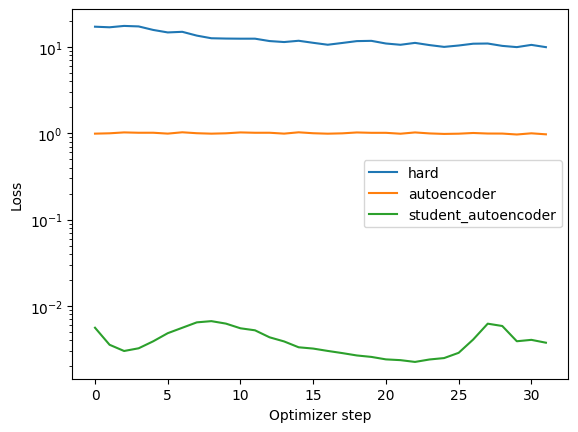

In [4]:
import matplotlib.pyplot as plt
for key in ('hard','autoencoder','student_autoencoder'):
    plt.plot([r['step'] for r in pilot['history']], [r[key] for r in pilot['history']], label=key)
plt.yscale('log'); plt.xlabel('Optimizer step'); plt.ylabel('Loss'); plt.legend(); plt.show()

The trace retains all 32 steps, including fluctuations, rather than presenting only favorable endpoints. It cannot establish anomaly discrimination or convergence.

## 14. Compute feasibility

The pilot step time can project an approximate 70,000-step paper-budget fit. Multiply by 45 for the requested all-category three-seed benchmark, then add data loading, evaluation and thermal margin. This extrapolation is not a measured full training runtime. Deterministic batch-one latency has a substantial p95 tail and needs further characterization.

In [5]:
seconds = pilot['seconds_per_step']
print({'estimated_70000_step_hours_per_model':seconds*70000/3600, 'estimated_45_model_training_hours':seconds*70000*45/3600, 'latency_ms':pilot['model_latency_ms']})

{'estimated_70000_step_hours_per_model': 3.048557664932458, 'estimated_45_model_training_hours': 137.18509492196063, 'latency_ms': {'p50': 33.47220001160167, 'p95': 145.27197999705095, 'warmup': 20, 'iterations': 100}}


At .1568 seconds per pilot step, linear projection is about 3.049 hours per 70k-step fit and 137.19 hours for 45 fits, excluding overhead. A full run is not yet validated; latency tails and sustained thermal behavior remain uncertain.

## 15. Bounded development plan

Proposed cap: 12 fits total, bottle and carpet, 2,000 steps each, seed 2026. Questions cover mean versus hard loss, AE contribution, map normalization, aggregation and capacity/budget. Penalty contrast requires legitimate documented external inputs and replaces another trial. No development fits have executed or been selected/rejected.

## 16. Model selection and calibration

Pending. No frozen final configuration or calibrated threshold exists. Later use development normals and fitting-derived synthetic proxies for selection, reserved calibration normals for strict score>threshold. Report sample size, nominal/observed FPR and uncertainty; no retrospective test tuning.

## 17. Frozen benchmark and metrics

Pending: zero final category-seed evaluations out of target 45. Image AUROC/AP, pixel AUROC/AP, AU-PRO, recall, FPR, precision and F1 are unavailable. No final metrics can be inferred from this normal-only pilot.

## 18. Failure analysis

Pending genuine test examples from all 15 categories after freeze. No false positive/negative claims are made. Later inspect scratches, textures, halos, logical/structural anomalies and localized responses missed by max aggregation alongside original images and masks; keep image panels local.

## 19. Six-model comparison

Pending EfficientAD evaluation. Previous Basic CNN, convolutional autoencoder, PatchCore, SuperSimpleNet Lite and PaDiM records remain unchanged. Later comparisons must match categories and report paired uncertainty, nine metrics, compute, memory and storage without unsupported superiority claims.

## 20. Validation, limitations and recovery

Focused core tests and deep pilot identity validation are provided. This notebook is a pilot-stage research record, not a completed milestone. No external penalty, only eight normals, fixed augmentation and 32 steps limit conclusions. Full development, calibration, benchmark, failure analysis and comparison remain. Notebook 07 is not started. Recovery instructions and current Git status are in docs/milestone_status.md.